# 02. Morphology space
Choose the morphology measure and turn it into a small set of axes that describe variation within cell families. 

In [1]:
# Import packages, set seed and define directories 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 12345
np.random.seed(SEED)
rng = np.random.default_rng(SEED) 

# Set the paths 

DATA = Path("mini-atlas/data")
QC = Path("results/QC")
OUT = Path("results/morphology")
OUT.mkdir(parents=True, exist_ok=True)

# 1. Load data 

In [2]:
# Load the covariates and the morphologies 

covars = pd.read_csv(QC / "covars.csv", index_col=0, dtype={"batch": str})
morph = pd.read_csv(DATA / "m1_patchseq_morph_features.csv", index_col=0).loc[covars.index]
print("cells:", len(covars), "| morphology table:", morph.shape)

cells: 605 | morphology table: (605, 63)


# 2. Morphology exploration 

In [3]:
# Check the morphologies 
groups = {
    "dendrite": [c for c in morph.columns if c.startswith("dendrite")],
    "stems":    [c for c in morph.columns if c.startswith("stems")],
    "axon":     [c for c in morph.columns if c.startswith("axon")],
    "apical":   [c for c in morph.columns if c.startswith('"apical"')],
    "other":    [c for c in morph.columns
                 if not c.startswith(("dendrite", "stems", "axon", '"apical"'))],
}
for name, cols in groups.items():
    print(f"\n{name} ({len(cols)}):")
    for c in cols:
        print("   ", c)


dendrite (22):
    dendrite above soma
    dendrite bifurcation standard deviation
    dendrite branch points
    dendrite first bifurcation moment
    dendrite height
    dendrite log max tortuosity
    dendrite log median tortuosity
    dendrite log min tortuosity
    dendrite max Euclidean dist
    dendrite max branch order
    dendrite max path distance to soma
    dendrite max segment length
    dendrite mean neurite radius
    dendrite median path angle
    dendrite min branch angle
    dendrite robust height
    dendrite robust width
    dendrite tips
    dendrite total length
    dendrite width
    dendrite x-bias
    dendrite z-bias

stems (4):
    stems
    stems exiting down
    stems exiting to the sides
    stems exiting up

axon (19):
    axon above soma
    axon bifurcation standard deviation
    axon branch points
    axon first bifurcation moment
    axon height
    axon log min tortuosity
    axon max Euclidean dist
    axon max branch order
    axon max path distanc

In [4]:
# Check which morphology features are found in excitatory and inhibitory neurons 

avail = morph.drop(columns=["cell class", "normalized layer"]).notna().groupby(morph["cell class"]).mean().T
print(avail.round(2).to_string())

cell class                                   exc   inh
"apical" branch points                       1.0  0.00
"apical" height                              1.0  0.00
"apical" log1p number of outer bifurcations  1.0  0.00
"apical" mean bifurcation distance           1.0  0.00
"apical" robust height                       1.0  0.00
"apical" robust width                        1.0  0.00
"apical" std bifurcation distance            1.0  0.00
"apical" total length                        1.0  0.00
"apical" width                               1.0  0.00
EMD axon dendrite                            0.0  1.00
Log1p fraction of axon above dendrite        0.0  1.00
Log1p fraction of axon below dendrite        0.0  1.00
Log1p fraction of dendrite above axon        0.0  1.00
axon above soma                              0.0  1.00
axon bifurcation standard deviation          0.0  1.00
axon branch points                           0.0  1.00
axon first bifurcation moment                0.0  1.00
axon heigh

## 3. Define the morphology measure: shared dendrite and soma features
A feature is kept if it is measured in at least 95% of both excitatory and inhibitory cells. 

In [5]:
# Make sure that the features are measured in at least 95% of both types of neurons 
shared = avail[(avail["exc"] >= 0.95) & (avail["inh"] >= 0.95)].index.tolist()
shared = [c for c in shared if c != "normalized depth"]       # a position in cortex, not a shape
print("shared morphology features:", len(shared))

mf = morph[shared]
print("cells with remaining gaps:", int(mf.isna().any(axis=1).sum()))
mf = mf.dropna()
print("final morphology table:", mf.shape)
print(shared)

shared morphology features: 23
cells with remaining gaps: 2
final morphology table: (603, 23)
['dendrite bifurcation standard deviation', 'dendrite branch points', 'dendrite first bifurcation moment', 'dendrite height', 'dendrite log max tortuosity', 'dendrite log min tortuosity', 'dendrite max Euclidean dist', 'dendrite max branch order', 'dendrite max path distance to soma', 'dendrite max segment length', 'dendrite mean neurite radius', 'dendrite robust height', 'dendrite robust width', 'dendrite tips', 'dendrite total length', 'dendrite width', 'dendrite x-bias', 'dendrite z-bias', 'soma radius', 'stems', 'stems exiting down', 'stems exiting to the sides', 'stems exiting up']


# 4. Check feature distributions 

In [6]:
# Import library 
from scipy.stats import skew 

# Calculate skewness of every column in shared morphology data 
sk = mf.apply(skew).sort_values(ascending=False)
print(sk.round(2).to_string())

soma radius                                3.17
dendrite log min tortuosity                2.64
dendrite log max tortuosity                2.04
dendrite x-bias                            1.96
dendrite first bifurcation moment          1.69
dendrite bifurcation standard deviation    1.62
dendrite max branch order                  1.27
dendrite max segment length                1.24
dendrite max Euclidean dist                1.23
dendrite max path distance to soma         1.21
dendrite total length                      1.21
dendrite robust height                     1.13
dendrite z-bias                            1.02
dendrite height                            0.98
stems                                      0.93
dendrite branch points                     0.93
dendrite robust width                      0.86
dendrite tips                              0.84
stems exiting down                         0.51
stems exiting up                           0.46
dendrite width                          

In [7]:
# Sanity check 

skewed = sk[sk > 1].index.tolist()
mins = mf[skewed].min().round(3)
print(mins.to_string())
print("\nfeatures with negative values:", mins[mins < 0].index.tolist())

soma radius                                  5.267
dendrite log min tortuosity                  0.000
dendrite log max tortuosity                  0.129
dendrite x-bias                              0.020
dendrite first bifurcation moment         -102.745
dendrite bifurcation standard deviation      0.000
dendrite max branch order                    1.000
dendrite max segment length                 46.068
dendrite max Euclidean dist                 30.616
dendrite max path distance to soma          46.068
dendrite total length                       58.603
dendrite robust height                      13.700
dendrite z-bias                           -338.020

features with negative values: ['dendrite first bifurcation moment', 'dendrite z-bias']


In [8]:
# Transform the numerical values in mf to make their distributions less skewed, standardise the features, and then identifiy 5 columns that remain the most skewed after transformation 

from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson", standardize=True)   # also z-scores each feature
mf_y = pd.DataFrame(pt.fit_transform(mf), index=mf.index, columns=mf.columns)
print(mf_y.apply(skew).abs().sort_values(ascending=False).round(2).head(5).to_string())

dendrite z-bias                      0.14
dendrite log min tortuosity          0.13
dendrite first bifurcation moment    0.07
dendrite robust width                0.04
dendrite branch points               0.04


In [9]:
# Run correlation to find features that are near-copies of each other, so that the PCA doesn't count the same information several times 

corr = mf_y.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False)
print(f"pairs with |r| > 0.9: {len(high)}")
print(high.round(2).to_string())

pairs with |r| > 0.9: 11
dendrite height                          dendrite robust height                0.99
dendrite branch points                   dendrite tips                         0.99
dendrite max Euclidean dist              dendrite max path distance to soma    0.98
dendrite robust width                    dendrite width                        0.97
dendrite height                          dendrite max Euclidean dist           0.94
dendrite max Euclidean dist              dendrite robust height                0.94
dendrite height                          dendrite max path distance to soma    0.93
dendrite max path distance to soma       dendrite robust height                0.92
dendrite tips                            dendrite total length                 0.92
dendrite bifurcation standard deviation  dendrite robust height                0.91
dendrite branch points                   dendrite total length                 0.91


In [10]:
# Remove near-duplicate features  
drop = ["dendrite height", "dendrite tips",
        "dendrite max path distance to soma", "dendrite width"]
mf_final = mf_y.drop(columns=drop)
print("features kept:", mf_final.shape[1], "| cells:", mf_final.shape[0])

# Run correlation again 
corr = mf_final.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("remaining pairs with |r| > 0.9:")
print(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).round(2).to_string())

features kept: 19 | cells: 603
remaining pairs with |r| > 0.9:
dendrite max Euclidean dist              dendrite robust height    0.94
dendrite bifurcation standard deviation  dendrite robust height    0.91
dendrite branch points                   dendrite total length     0.91


In [11]:
# Remove cell-family means 

fam = covars.loc[mf_final.index, "rna_family"]

# How much of each feature is explained by cell family (R²), before centring
within_var = (mf_final - mf_final.groupby(fam).transform("mean")).var(ddof=0)
r2_before = (1 - within_var / mf_final.var(ddof=0)).sort_values(ascending=False)
print(r2_before.round(2).to_string())
print("\nmean across features:", round(r2_before.mean(), 2))

# Remove family means, then rescale so every feature has unit variance again
mf_w = mf_final - mf_final.groupby(fam).transform("mean")
mf_w = mf_w / mf_w.std(ddof=0)
print("\ncentred table:", mf_w.shape)

dendrite max branch order                  0.56
dendrite max Euclidean dist                0.51
dendrite z-bias                            0.50
dendrite robust height                     0.47
dendrite total length                      0.47
dendrite bifurcation standard deviation    0.45
dendrite branch points                     0.41
dendrite first bifurcation moment          0.40
stems                                      0.23
dendrite max segment length                0.22
stems exiting to the sides                 0.17
dendrite log max tortuosity                0.16
dendrite robust width                      0.15
dendrite log min tortuosity                0.14
stems exiting up                           0.08
stems exiting down                         0.08
soma radius                                0.06
dendrite mean neurite radius               0.04
dendrite x-bias                            0.02

mean across features: 0.27

centred table: (603, 19)


# 5. Run PCA 

In [12]:
from sklearn.decomposition import PCA

pca_w = PCA(random_state=SEED).fit(mf_w)
var_w = pca_w.explained_variance_ratio_
print("variance explained, centred (first 8 PCs):", var_w[:8].round(3))
print("cumulative:", var_w.cumsum()[:8].round(3))

# comparison: how much of the first 4 PCs is just cell family, with and without centring
def fam_r2(df):
    return 1 - (df - df.groupby(fam).transform("mean")).var(ddof=0) / df.var(ddof=0)

names = [f"PC{i}" for i in range(1, 5)]
pcs_raw = pd.DataFrame(PCA(random_state=SEED).fit_transform(mf_final)[:, :4], index=mf_final.index, columns=names)
pcs_w = pd.DataFrame(pca_w.transform(mf_w)[:, :4], index=mf_w.index, columns=names)
print("\nshare of each PC explained by cell family:")
print(pd.DataFrame({"not centred": fam_r2(pcs_raw), "centred": fam_r2(pcs_w)}).round(2))

variance explained, centred (first 8 PCs): [0.309 0.112 0.095 0.091 0.061 0.053 0.048 0.047]
cumulative: [0.309 0.421 0.516 0.607 0.668 0.721 0.77  0.817]

share of each PC explained by cell family:
     not centred  centred
PC1         0.54      0.0
PC2         0.16      0.0
PC3         0.16      0.0
PC4         0.18      0.0


In [13]:
# Set figure directory 
FIGS = Path("results/morphology/figures")
FIGS.mkdir(parents=True, exist_ok=True)

PCs above the shuffled null (95th percentile): 4


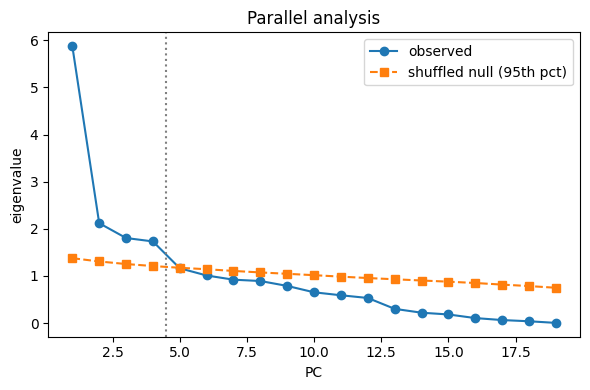

In [14]:
# How many PCs to keep 

X = mf_w.values
obs = np.linalg.eigvalsh(np.corrcoef(X, rowvar=False))[::-1]     # eigenvalues, largest first

n_iter = 200
null = np.empty((n_iter, X.shape[1]))
for i in range(n_iter):
    Xp = np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])
    null[i] = np.linalg.eigvalsh(np.corrcoef(Xp, rowvar=False))[::-1]
thr = np.percentile(null, 95, axis=0)

k = int(np.argmax(obs <= thr)) if (obs <= thr).any() else len(obs)
print("PCs above the shuffled null (95th percentile):", k)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(obs) + 1), obs, "o-", label="observed")
ax.plot(range(1, len(thr) + 1), thr, "s--", label="shuffled null (95th pct)")
ax.axvline(k + 0.5, color="grey", ls=":")
ax.set(xlabel="PC", ylabel="eigenvalue", title="Parallel analysis")
ax.legend()
plt.tight_layout()
fig.savefig(FIGS / "PCs.png", dpi=300, bbox_inches="tight")   # save before show
plt.show()


wPC1  (variance explained: 30.9%)
  positive: dendrite total length (+0.38), dendrite max Euclidean dist (+0.35), dendrite robust height (+0.34), dendrite bifurcation standard deviation (+0.33)
  negative: dendrite log min tortuosity (-0.18), dendrite mean neurite radius (-0.14), stems exiting up (-0.02)

wPC2  (variance explained: 11.2%)
  positive: stems exiting to the sides (+0.50), dendrite robust width (+0.34), dendrite max segment length (+0.22), dendrite x-bias (+0.20)
  negative: stems exiting down (-0.39), dendrite first bifurcation moment (-0.36), dendrite z-bias (-0.34)

wPC3  (variance explained: 9.5%)
  positive: stems exiting up (+0.48), dendrite max segment length (+0.18), stems exiting down (+0.14), dendrite x-bias (+0.13)
  negative: stems exiting to the sides (-0.49), dendrite z-bias (-0.46), dendrite first bifurcation moment (-0.44)

wPC4  (variance explained: 9.1%)
  positive: dendrite branch points (+0.34), dendrite log max tortuosity (+0.31), stems (+0.23), soma 

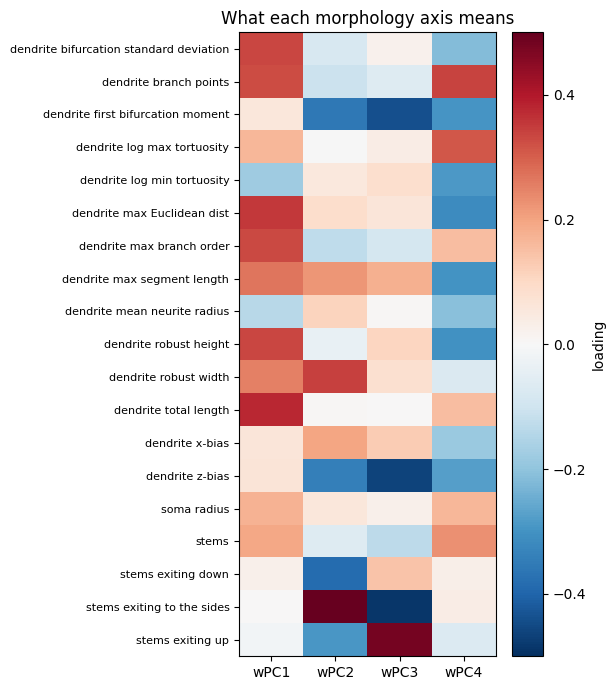

In [15]:
# Build and name morphology axes 

k = 4
names = [f"wPC{i}" for i in range(1, k + 1)]

pca4 = PCA(n_components=k, random_state=SEED).fit(mf_w)
loadings = pd.DataFrame(pca4.components_.T, index=mf_w.columns, columns=names)

# PC signs are arbitrary, so fix the convention: positive loading on total dendritic length
for c in names:
    if loadings.loc["dendrite total length", c] < 0:
        loadings[c] *= -1

# axis scores per cell, rescaled to unit SD so effects later are "per 1 SD of the axis"
scores = pd.DataFrame((mf_w - mf_w.mean()).values @ loadings.values, index=mf_w.index, columns=names)
scores = scores / scores.std(ddof=0)

# strongest features per axis
for c in names:
    s = loadings[c].sort_values()
    print(f"\n{c}  (variance explained: {pca4.explained_variance_ratio_[names.index(c)]:.1%})")
    print("  positive:", ", ".join(f"{i} ({v:+.2f})" for i, v in s.tail(4).iloc[::-1].items()))
    print("  negative:", ", ".join(f"{i} ({v:+.2f})" for i, v in s.head(3).items()))

# loadings heatmap
fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(loadings, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(k), names)
ax.set_yticks(range(len(loadings)), loadings.index, fontsize=8)
plt.colorbar(im, ax=ax, label="loading")
ax.set_title("What each morphology axis means")
plt.tight_layout() 
fig.savefig(FIGS / "PC_meaning.png", dpi=300, bbox_inches="tight") 
plt.show()

In [16]:
# Do the axes track technical covariates or cortical depth?
chk = pd.concat([scores, covars.loc[scores.index, ["log10_ngenes", "intron_frac", "norm_depth"]]], axis=1)
print(chk.corr().loc[names, ["log10_ngenes", "intron_frac", "norm_depth"]].round(2))

      log10_ngenes  intron_frac  norm_depth
wPC1          0.09         0.02        0.18
wPC2         -0.05         0.00        0.19
wPC3         -0.06        -0.01        0.08
wPC4         -0.07        -0.09       -0.09


In [17]:
# Save files 
scores.to_csv(OUT / "morph_pcs.csv")
mf_w.to_csv(OUT / "morph_features_within.csv")
loadings.to_csv(OUT / "pc_loadings.csv") 

# naive global axes (no family centring), kept only for the naive comparison in notebook 03
g = pcs_raw / pcs_raw.std(ddof=0)
g.columns = [f"gPC{i}" for i in range(1, 5)]
pd.concat([scores, g], axis=1).to_csv(OUT / "morph_pcs.csv")
print(sorted(p.name for p in OUT.iterdir()))

['.DS_Store', 'figures', 'morph_features_within.csv', 'morph_pcs.csv', 'pc_loadings.csv']
